# 02. Признаки, обучение, подбор гиперпараметров, оценка и анализ ошибок

**Задача:** для каждого из 15 рядов продаж предсказать число продаж в каждый из **28 следующих дней**.
Тип задачи — **регрессия** на временных рядах (целевая переменная `y` — неотрицательное целое: число продаж за день).

**Стратегия прогноза — прямая (direct):** одна модель прогнозирует день `t`, используя только данные до дня `t − 28`.
Так одна модель честно даёт прогноз на любой день из ближайших 4 недель, а в признаки никогда не попадает «будущее».

План ноутбука:
1. признаки и разбиение по времени;
2. два бейзлайна;
3. четыре ML-модели с параметрами по умолчанию (сравнение на валидации);
4. подбор гиперпараметров LightGBM в Optuna;
5. финальная оценка на тесте (один раз) и скользящий бэктест;
6. анализ ошибок и важность признаков;
7. итоговая модель и прогноз на 28 дней вперёд.

In [1]:
import sys, warnings, json
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.pipeline import make_dataset, split, fit_predict, tune_lgbm, backtest, event_mask
from src.features import feature_columns, build_features, add_future
from src.models import MODELS, LGBMModel, LGBM_DEFAULT, baseline_naive_28, baseline_same_dow_4w
from src.metrics import summary, per_series, wape
from src.plotting import setup, month_axis, save
setup(); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)

df, feats = make_dataset()
cols = feature_columns(feats)
print('Строк с признаками:', feats.shape[0], '| признаков:', len(cols))

Строк с признаками: 18477 | признаков: 37


## 1. Признаки

Все признаки строятся в `src/features.py`. Принцип: **для дня t используем только значения ряда до дня t − 28** и календарь (он известен заранее).

| группа | признаки | зачем |
|---|---|---|
| идентификатор ряда | `series`, `product_group` (категориальные) | одна глобальная модель на все ряды знает, какой ряд прогнозирует |
| лаги | `lag_28`, `lag_35` … `lag_63`, `lag_91`, `lag_182`, `lag_364` | продажи 4–9 недель назад в **тот же день недели**, квартал, полгода, год назад |
| уровень ряда | `same_dow_mean_4/8`, `roll_mean_7…91`, `workday_mean_28` | недавний уровень продаж (среднее по тому же дню недели, по рабочим дням) |
| изменчивость | `roll_std_28`, `roll_max_28`, `zero_share_28` | насколько ряд «шумный» и как часто в нём нули |
| тренд | `trend_7_91`, `trend_28_91` | растёт ли ряд (недавний уровень / квартальный) |
| год назад | `yoy_mean_28` | уровень вокруг той же даты прошлого года (годовая сезонность) |
| календарь | `dow`, `dom`, `month`, `weekofyear`, `days_to_month_end`, `is_holiday`, `is_nonwork`, `nonwork_before`, `pre_nonwork` | выходные, праздники КР, длинные выходные, эффект понедельника |
| ограничение выдач | `credit_supply_limit`, `limit_share_lag_window` | ограничение предложения кредитов 10.2023–02.2024 |
| возраст ряда | `days_since_start` | молодые продукты (копилка) ведут себя иначе |

Строки, где ещё нет квартальной истории (первые ~4 месяца каждого ряда), не используются — признаки там неполные.

In [2]:
feats[['date', 'series', 'y', 'lag_28', 'same_dow_mean_4', 'roll_mean_28', 'trend_28_91', 'dow', 'is_nonwork', 'nonwork_before']].sample(6, random_state=1)

,date,series,y,lag_28,same_dow_mean_4,roll_mean_28,trend_28_91,dow,is_nonwork,nonwork_before
7841,2025-11-08,Карта: Зарплатные,0.0,0.0,0.00,246.392857,0.973293,5,1,0
153,2023-08-22,Депозит: Классические срочные,6.0,7.0,6.50,4.785714,0.791818,1,0,0
4518,2023-10-24,Карта: Visa/MC массовые (именные + предвыпущен...,310.0,605.0,454.75,309.392857,1.177629,1,0,0
12976,2025-10-18,Карта: Элкарт розница,0.0,0.0,0.00,11.178571,0.845594,5,1,0
13501,2023-09-18,"Кредит: Ипотека, авто и прочие",1.0,3.0,2.00,1.250000,0.546875,0,0,2
12263,2023-11-05,Карта: Элкарт розница,0.0,0.0,0.00,43.857143,1.116364,6,1,1


## 2. Разбиение по времени

Случайное разбиение для временных рядов **нельзя**: модель увидела бы будущее (соседние дни сильно похожи), и метрика была бы завышена.
Делим строго по времени:

* **train** — 2023 → 31.03.2026: обучение;
* **validation** — апрель–июнь 2026: сравнение моделей и подбор гиперпараметров;
* **test** — июль–сентябрь 2026: финальная оценка, используется **один раз** в конце.

Для теста модель переобучается на train + validation (так она будет работать в жизни — на всех доступных данных).

train: 15732 строк (2023-03-22 … 2026-03-31)
val:   1365 строк (2026-04-01 … 2026-06-30)
test:  1380 строк (2026-07-01 … 2026-09-30)


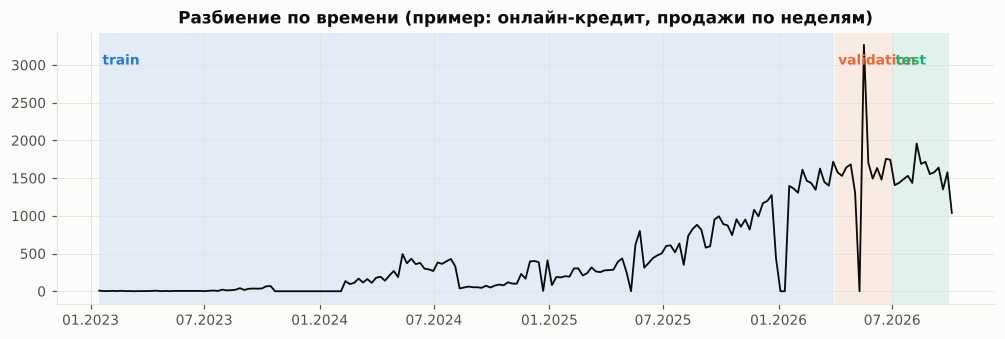

In [3]:
tr, va, te = split(feats)
print(f'train: {len(tr)} строк ({tr.date.min().date()} … {tr.date.max().date()})')
print(f'val:   {len(va)} строк ({va.date.min().date()} … {va.date.max().date()})')
print(f'test:  {len(te)} строк ({te.date.min().date()} … {te.date.max().date()})')

s = df[df.series == 'Кредит: Онлайн кредит'].set_index('date').y.resample('W').sum()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(s.index, s.values, color=C.COLORS['actual'], lw=1.2)
for (a, b, lab, col) in [(s.index.min(), C.TRAIN_END, 'train', C.COLORS['s1']), (C.VAL_START, C.VAL_END, 'validation', C.COLORS['s2']), (C.TEST_START, C.TEST_END, 'test', C.COLORS['s3'])]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=0.12, lw=0)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=5), s.max() * 0.92, lab, color=col, fontsize=9, fontweight='bold')
ax.set_title('Разбиение по времени (пример: онлайн-кредит, продажи по неделям)'); month_axis(ax)
save(fig, 'model_split'); plt.show()

## 3. Метрики и бейзлайны

**Метрика — WAPE** = Σ|факт − прогноз| / Σ факт (доля ошибки от объёма продаж). Почему:
* нули в данных (выходные) — MAPE делит на ноль, WAPE — нет;
* понятна бизнесу: «WAPE 0,25» = ошибаемся на 25 % от объёма продаж;
* вес ряда пропорционален его объёму — крупные продукты важнее для плана.

Дополнительно смотрим: **WAPE за неделю и за месяц** (бизнес планирует неделями / месяцами, дневные ошибки частично гасятся), **macro-WAPE** (среднее по рядам — чтобы маленькие ряды тоже были видны), **MAE / RMSE** (в штуках), **Bias** (знак систематической ошибки).

**Бейзлайны** — то, что аналитик сделал бы без ML:
* `naive_28` — «как 4 недели назад в тот же день недели»;
* `same_dow_4w` — среднее за 4 последние известные недели по тому же дню недели (устойчивее к всплескам).

ML-модель имеет смысл, только если она заметно лучше бейзлайна.

In [4]:
val = va[['date', 'product_group', 'series', 'y']].copy()
val['naive_28'] = baseline_naive_28(va)
val['same_dow_4w'] = baseline_same_dow_4w(va)
summary(val, ['naive_28', 'same_dow_4w']).round(3)

,WAPE,WAPE_week,WAPE_month,macro_WAPE,MAE,RMSE,Bias
model,,,,,,,
naive_28,0.497,0.354,0.147,0.602,56.63,162.569,-0.004
same_dow_4w,0.372,0.271,0.140,0.471,42.31,122.517,0.001


## 4. Четыре ML-модели с параметрами по умолчанию

Все модели — **глобальные** (одна модель на 15 рядов, ряд — категориальный признак): маленькие ряды получают общие закономерности от больших.

* **Ridge** — линейная регрессия с L2-регуляризацией. Простая и интерпретируемая; L2 штрафует большие коэффициенты и спасает от мультиколлинеарности признаков уровня. Чтобы учесть свой недельный профиль у каждого ряда, добавлен признак «ряд × день недели». Цель — `log1p(y)`.
* **RandomForest** — среднее по сотням деревьев, каждое обучено на бутстрэп-выборке и случайном подмножестве признаков. Ловит нелинейности, устойчив, но не экстраполирует тренд за пределы обучающих значений. Цель — `log1p(y)`.
* **LightGBM** — градиентный бустинг: деревья строятся последовательно, каждое следующее учится на ошибках (градиентах функции потерь) предыдущих. Быстрый, сам работает с категориями и пропусками. Функция потерь Tweedie подходит для счётных данных с большим числом нулей.
* **CatBoost** — градиентный бустинг на симметричных деревьях со встроенным кодированием категорий (ordered target statistics, без утечки). Цель — `log1p(y)`.

In [5]:
import time
times = {}
for name in MODELS:
    t0 = time.time()
    _, val[name] = fit_predict(name, {}, tr, va, cols)
    times[name] = round(time.time() - t0, 1)
m_val = summary(val, ['naive_28', 'same_dow_4w', *MODELS])
m_val['fit_sec'] = pd.Series(times)
m_val.round(3)

,WAPE,WAPE_week,WAPE_month,macro_WAPE,MAE,RMSE,Bias,fit_sec
model,,,,,,,,
naive_28,0.497,0.354,0.147,0.602,56.630,162.569,-0.004,NaN
same_dow_4w,0.372,0.271,0.140,0.471,42.310,122.517,0.001,NaN
Ridge,0.345,0.287,0.255,0.407,39.247,117.889,-0.138,0.3
RandomForest,0.259,0.197,0.171,0.363,29.487,96.946,-0.062,15.7
LightGBM,0.245,0.178,0.155,0.343,27.927,85.060,-0.025,2.0
CatBoost,0.251,0.186,0.145,0.362,28.602,92.113,-0.044,6.8


**Комментарий.** Все ML-модели лучше обоих бейзлайнов по дневному WAPE, лучшая — LightGBM, CatBoost совсем рядом. Ridge заметно слабее деревьев: связи между признаками и продажами нелинейны (например, эффект понедельника зависит от того, были ли праздники), а линейная модель такие взаимодействия сама не строит. Дальше настраиваю лучшую модель — LightGBM.

## 5. Подбор гиперпараметров LightGBM (Optuna)

In [6]:
t0 = time.time()
study = tune_lgbm(tr, va, cols, n_trials=40)
print(f'Подбор занял {time.time() - t0:.0f} c; лучший WAPE на валидации: {study.best_value:.4f}')
best = study.best_params
best

Подбор занял 154 c; лучший WAPE на валидации: 0.2237


{'objective': 'poisson',
 'learning_rate': 0.03465156905622393,
 'num_leaves': 49,
 'min_child_samples': 28,
 'feature_fraction': 0.7076651794629198,
 'bagging_fraction': 0.9339267483363018,
 'lambda_l2': 16.909204358540762,
 'n_estimators': 1300}

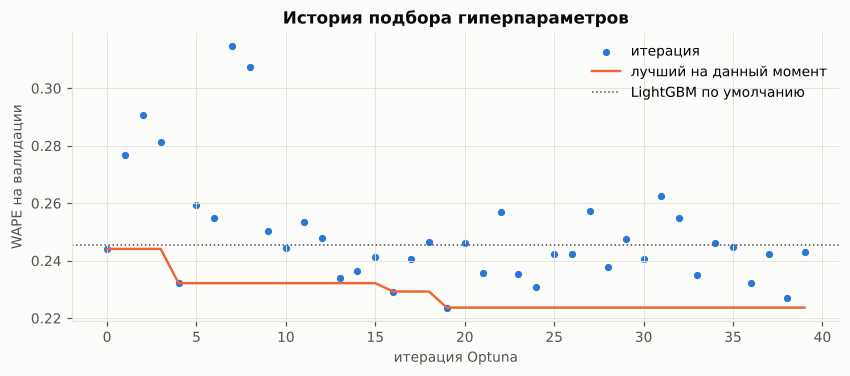

Важность гиперпараметров (fANOVA):
bagging_fraction          0.284
feature_fraction          0.268
n_estimators              0.211
learning_rate             0.142
lambda_l2                 0.049
min_child_samples         0.029
num_leaves                0.011
objective                 0.006
tweedie_variance_power    0.000
dtype: float64


In [7]:
tr_df = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.scatter(tr_df.number, tr_df.value, s=14, color=C.COLORS['s1'], label='итерация')
ax.plot(tr_df.number, tr_df.value.cummin(), color=C.COLORS['s2'], label='лучший на данный момент')
ax.axhline(m_val.loc['LightGBM', 'WAPE'], color=C.COLORS['muted'], ls=':', lw=1, label='LightGBM по умолчанию')
ax.set_xlabel('итерация Optuna'); ax.set_ylabel('WAPE на валидации'); ax.set_title('История подбора гиперпараметров'); ax.legend()
save(fig, 'model_optuna_history'); plt.show()
try:
    import optuna
    imp = optuna.importance.get_param_importances(study)
    print('Важность гиперпараметров (fANOVA):'); print(pd.Series(imp).round(3))
except Exception as e:
    print('Важность гиперпараметров недоступна:', e)

In [8]:
_, val['LightGBM_tuned'] = fit_predict('LightGBM', best, tr, va, cols)
cmp = summary(val, ['same_dow_4w', 'LightGBM', 'LightGBM_tuned']).round(3)
cmp

,WAPE,WAPE_week,WAPE_month,macro_WAPE,MAE,RMSE,Bias
model,,,,,,,
same_dow_4w,0.372,0.271,0.140,0.471,42.310,122.517,0.001
LightGBM,0.245,0.178,0.155,0.343,27.927,85.060,-0.025
LightGBM_tuned,0.224,0.153,0.125,0.325,25.464,82.517,-0.022


**Как оптимизация повлияла на метрики.** В таблице выше три строки: бейзлайн, LightGBM по умолчанию и LightGBM после Optuna. Подбор снизил WAPE на валидации: дневной с 0,245 до 0,224, недельный с 0,178 до 0,153, месячный с 0,155 до 0,125. Лучшая функция потерь — Poisson. По оценке fANOVA на качество сильнее всего влияют доля строк и доля признаков на дерево и число деревьев, затем темп обучения. Выбор функции потерь почти не влияет: Poisson и Tweedie дают близкий результат.

⚠️ Валидация использовалась для выбора модели и параметров, поэтому её оценка **оптимистична**. Честную оценку даёт только тест.

## 6. Финальная оценка на тесте (июль–сентябрь 2026)

In [9]:
trva = pd.concat([tr, va])
test = te[['date', 'product_group', 'series', 'y']].copy()
test['naive_28'] = baseline_naive_28(te)
test['same_dow_4w'] = baseline_same_dow_4w(te)
for name in MODELS:
    _, test[name] = fit_predict(name, {}, trva, te, cols)
tuned, test['LightGBM_tuned'] = fit_predict('LightGBM', best, trva, te, cols)
models_all = ['naive_28', 'same_dow_4w', *MODELS, 'LightGBM_tuned']
m_test = summary(test, models_all)
m_test.round(3)

,WAPE,WAPE_week,WAPE_month,macro_WAPE,MAE,RMSE,Bias
model,,,,,,,
naive_28,0.403,0.293,0.210,0.485,52.357,346.307,-0.097
same_dow_4w,0.359,0.273,0.235,0.433,46.577,340.964,-0.087
Ridge,0.405,0.370,0.341,0.452,52.499,344.197,-0.200
RandomForest,0.328,0.281,0.251,0.381,42.589,338.346,-0.086
LightGBM,0.317,0.266,0.237,0.438,41.097,337.937,-0.099
CatBoost,0.373,0.330,0.298,0.419,48.428,341.361,-0.208
LightGBM_tuned,0.317,0.263,0.236,0.415,41.134,337.385,-0.080


В тест попало **разовое событие**: 2–8 сентября 2026 г. банк массово выпустил виртуальные карты нерезидентам — за неделю больше половины продаж этого ряда за весь квартал, в пиковый день в десятки раз больше обычного. Ни одна модель по истории такое предсказать не может — это видно по огромному RMSE у всех моделей. Поэтому показываю метрики ещё и **без этого события**, чтобы сравнить модели на «обычных» днях (событие исключено только из оценки, а не из данных).

In [10]:
m_test_clean = summary(test[event_mask(test)], models_all)
m_test_clean.round(3)

,WAPE,WAPE_week,WAPE_month,macro_WAPE,MAE,RMSE,Bias
model,,,,,,,
naive_28,0.325,0.205,0.103,0.459,36.977,97.029,0.026
same_dow_4w,0.274,0.182,0.132,0.405,31.187,78.653,0.037
Ridge,0.325,0.286,0.253,0.425,37.071,87.722,-0.091
RandomForest,0.238,0.184,0.150,0.351,27.150,64.010,0.039
LightGBM,0.225,0.167,0.133,0.408,25.651,59.796,0.024
CatBoost,0.289,0.240,0.203,0.390,32.936,72.518,-0.100
LightGBM_tuned,0.226,0.164,0.134,0.386,25.746,60.038,0.045


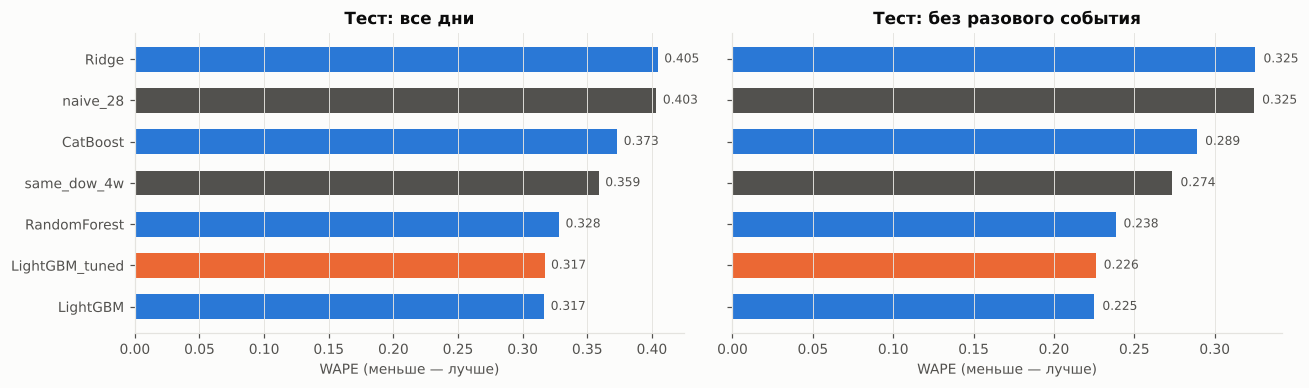

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (tab, title) in zip(axes, [(m_test, 'Тест: все дни'), (m_test_clean, 'Тест: без разового события')]):
    t = tab['WAPE'].sort_values()
    colors = [C.COLORS['s2'] if i == 'LightGBM_tuned' else (C.COLORS['muted'] if i in ('naive_28', 'same_dow_4w') else C.COLORS['s1']) for i in t.index]
    ax.barh(t.index, t.values, color=colors, height=0.6)
    for i, v in enumerate(t.values):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8, color=C.COLORS['muted'])
    ax.set_title(title); ax.set_xlabel('WAPE (меньше — лучше)'); ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, 'model_test_wape'); plt.show()

**Интерпретация результатов теста:**
* по **дневному** WAPE итоговая модель (LightGBM после Optuna) лучше обоих бейзлайнов — и с событием (0,317 против 0,359), и без него (0,226 против 0,274). LightGBM с параметрами по умолчанию на тесте практически такой же; выбор модели делался по валидации, и «задним числом» по тесту я его не меняю, иначе тест перестанет быть честной оценкой;
* на тесте выигрыш у бейзлайна меньше, чем на валидации: в июле–сентябре 2026 г. несколько рядов заметно менялись, а модель, видящая данные только до t − 28, тренд «догоняет» с запаздыванием;
* по **недельному** WAPE модель немного лучше бейзлайна, а по **месячному** — на его уровне (а простой «как 4 недели назад» по месяцу даже точнее). Причина: ML-модель лучше всего угадывает **распределение продаж по дням** (понедельники, праздники, дни после длинных выходных), а в месячной сумме эти выигрыши взаимно гасятся. Вывод для бизнеса: модель полезна прежде всего для **дневного и недельного планирования** (нагрузка отделений, лимиты выдач по дням); для месячного плана её стоит использовать вместе с экспертной корректировкой на тренды и кампании.

### Скользящий бэктест: стабилен ли выигрыш?
Один тестовый квартал — это мало. Повторяю «жизненный» сценарий 13 раз: в каждой точке отсчёта (с октября 2025 г. каждые 28 дней) модель обучается на всём, что было **до** неё, и прогнозирует 28 следующих дней.

In [12]:
bt, bt_pred = backtest(feats, cols, best)
bt['gain_%'] = ((1 - bt.WAPE_model / bt.WAPE_baseline) * 100).round(1)
print(f'Средний WAPE: модель {bt.WAPE_model.mean():.3f} | бейзлайн {bt.WAPE_baseline.mean():.3f}; модель лучше в {(bt.WAPE_model < bt.WAPE_baseline).sum()} из {len(bt)} окон')
bt.round(3)

Средний WAPE: модель 0.316 | бейзлайн 0.468; модель лучше в 11 из 13 окон


,origin,end,WAPE_model,WAPE_baseline,gain_%
0,2025-10-02,2025-10-29,0.206,0.222,7.2
1,2025-10-30,2025-11-26,0.375,0.410,8.3
2,2025-11-27,2025-12-24,0.362,0.439,17.5
3,2025-12-25,2026-01-21,0.396,1.490,73.4
4,2026-01-22,2026-02-18,0.500,0.489,-2.2
5,2026-02-19,2026-03-18,0.388,0.462,16.2
6,2026-03-19,2026-04-15,0.279,0.308,9.2
7,2026-04-16,2026-05-13,0.239,0.619,61.3
8,2026-05-14,2026-06-10,0.215,0.266,19.1
9,2026-06-11,2026-07-08,0.210,0.293,28.4


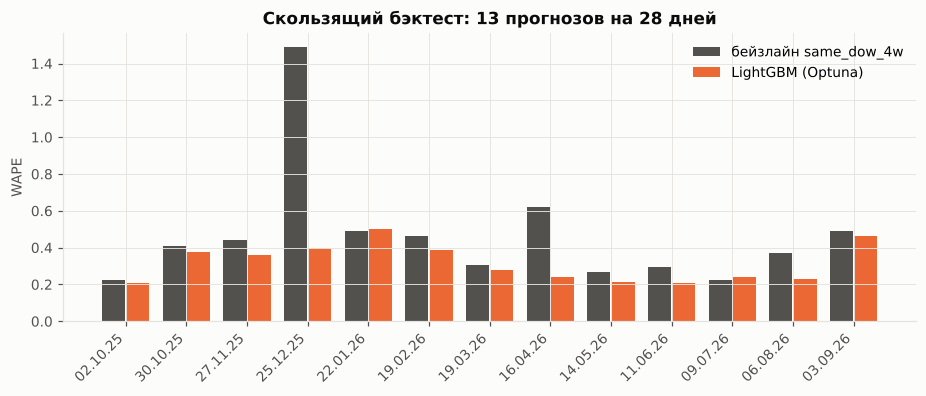

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(bt))
ax.bar(x - 0.2, bt.WAPE_baseline, width=0.38, color=C.COLORS['muted'], label='бейзлайн same_dow_4w')
ax.bar(x + 0.2, bt.WAPE_model, width=0.38, color=C.COLORS['s2'], label='LightGBM (Optuna)')
ax.set_xticks(x, [pd.Timestamp(o).strftime('%d.%m.%y') for o in bt.origin], rotation=45, ha='right')
ax.set_ylabel('WAPE'); ax.set_title('Скользящий бэктест: 13 прогнозов на 28 дней'); ax.legend()
save(fig, 'model_backtest'); plt.show()

Выигрыш модели у бейзлайна **устойчивый**: в среднем 0,316 против 0,468, модель лучше в 11 окнах из 13. Самый большой выигрыш приходится на окна с длинными праздниками: январь 2026 (новогодние каникулы 1–11 января) и май (майские каникулы). Бейзлайн «4 недели назад» переносит обычные продажи на праздничные дни и наоборот, а модель знает календарь. Окна, где обе модели ошибаются сильнее, — периоды кампаний (ноябрь–декабрь, сентябрь 2026).

⚠️ Окна апреля–июня 2026 г. совпадают с валидацией, по которой подбирались гиперпараметры, поэтому в них модель в чуть более выгодном положении. У окон до апреля и после июня такого преимущества нет.

## 7. Анализ ошибок: где и почему модель ошибается
### 7.1 По рядам

In [14]:
ps = per_series(test, 'LightGBM_tuned').join(per_series(test, 'same_dow_4w')[['WAPE']].rename(columns={'WAPE': 'WAPE_baseline'}))
ps['лучше бейзлайна'] = np.where(ps.WAPE < ps.WAPE_baseline, 'да', 'нет')
ps.round(3)

fact_total  pred_total   WAPE  WAPE_week   Bias  WAPE_baseline лучше бейзлайна
product_group series                                                                                                                            
Карта         Карта: Visa/MC массовые (именные + предвыпущенные)     40349.0   45739.884  0.175      0.153  0.134          0.201              да
              Карта: Нерезиденты                                     37520.0   13950.256  0.655      0.629 -0.628          0.667              да
              Карта: Зарплатные                                      23867.0   26541.158  0.321      0.213  0.112          0.364              да
              Карта: Виртуальные                                     20802.0   20541.449  0.251      0.204 -0.013          0.357              да
Кредит        Кредит: Онлайн кредит                                  20718.0   20904.271  0.175      0.097  0.009          0.247              да
              Кредит: Экспресс и кредит наличными                    12173.0   11892.075  0.141      0.076 -0.023          0.205              да
Депозит       Депозит: Онлайн-вклады                                  9313.0    9583.732  0.171      0.065  0.029          0.233              да
              Депозит: Копилка (онлайн)                               6090.0    5025.249  0.210      0.181 -0.175          0.227              да
Карта         Карта: Кредитные / рассрочка                            3583.0    4200.418  0.325      0.242  0.172          0.378              да
              Карта: Элкарт пенс/соц                                  1935.0    3127.321  0.683      0.643  0.616          0.488             нет
              Карта: Элкарт розница                                   1129.0     953.916  0.385      0.277 -0.155          0.435              да
Депозит       Депозит: Классические срочные                            604.0     655.819  0.372      0.270  0.086          0.395              да
Кредит        Кредит: Товарный кредит / рассрочка                      530.0    1221.120  1.345      1.332  1.304          1.176             нет
Депозит       Депозит: Пенсионные                                      328.0     323.538  0.332      0.184 -0.014          0.428              да
Кредит        Кредит: Ипотека, авто и прочие                           126.0     104.114  0.692      0.376 -0.174          0.696              да

Модель лучше бейзлайна в 13 из 15 рядов (колонка «лучше бейзлайна»).

* **Хорошо прогнозируются** крупные «регулярные» ряды: онлайн-кредит, экспресс-кредиты, Visa/MC массовые, онлайн-вклады, копилка (WAPE ≈ 0,14–0,21, недельный — ещё ниже).
* **Плохо — ряды, которые движутся кампаниями**: нерезиденты (массовый выпуск в сентябре), Элкарт пенс/соц (выпуск под соцвыплаты), зарплатные карты (запуск зарплатных проектов). Их продажи определяются событиями, о которых модель не знает; автокорреляция у них низкая (см. EDA).
* **Маленькие ряды** («Ипотека, авто и прочие» — меньше 1 продажи в день; «Товарный кредит» — продукт сворачивается) имеют высокий относительный WAPE, но их вклад в общую ошибку маленький.
* **Хуже бейзлайна** модель в двух рядах: «Элкарт пенс/соц» (завышает прогноз после прошлых волн выпуска) и «Товарный кредит» (в истории он был большим, а сейчас почти исчез — структурный сдвиг). Для таких рядов на практике можно оставить бейзлайн или ручную корректировку.

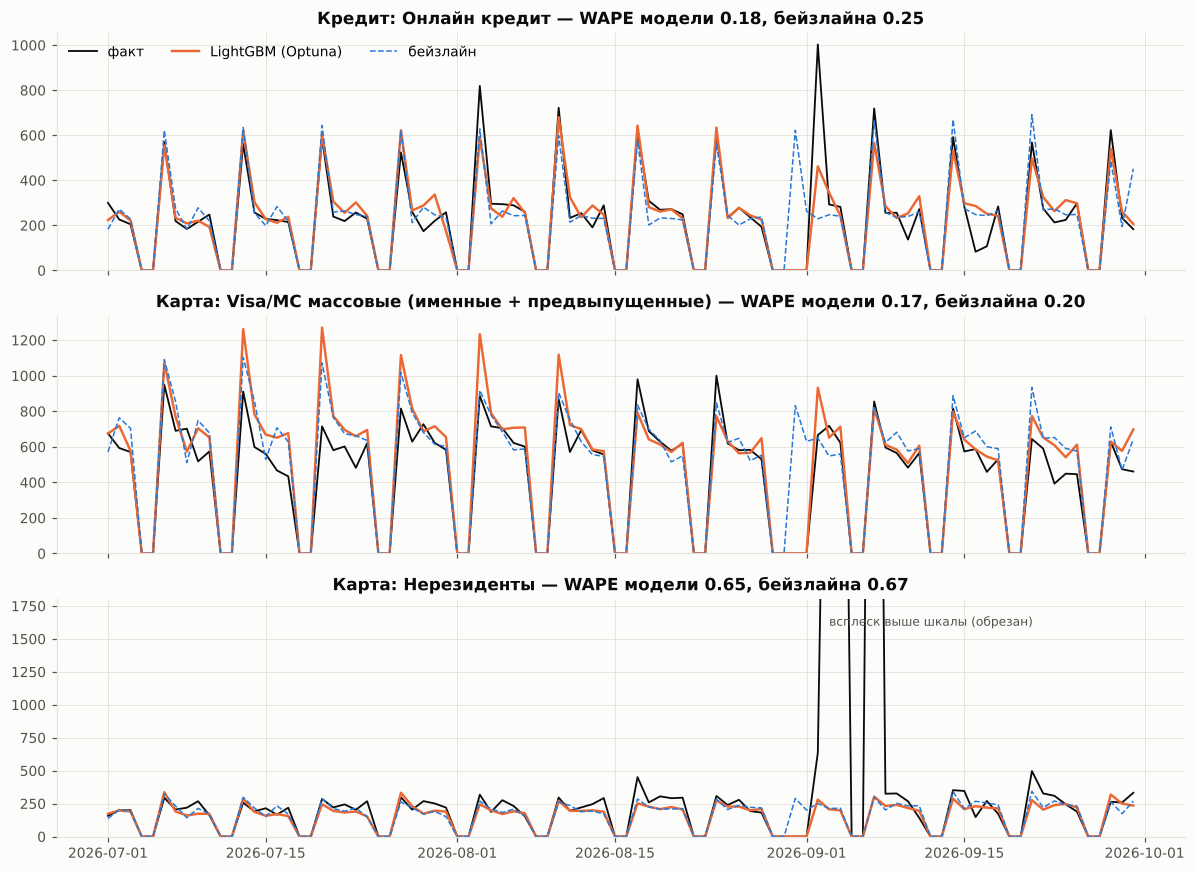

In [15]:
show = ['Кредит: Онлайн кредит', 'Карта: Visa/MC массовые (именные + предвыпущенные)', 'Карта: Нерезиденты']
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, s in zip(axes, show):
    g = test[test.series == s]
    ax.plot(g.date, g.y, color=C.COLORS['actual'], lw=1.2, label='факт')
    ax.plot(g.date, g.LightGBM_tuned, color=C.COLORS['s2'], label='LightGBM (Optuna)')
    ax.plot(g.date, g.same_dow_4w, color=C.COLORS['s1'], lw=1, ls='--', label='бейзлайн')
    ax.set_title(f"{s} — WAPE модели {wape(g.y, g.LightGBM_tuned):.2f}, бейзлайна {wape(g.y, g.same_dow_4w):.2f}")
    ax.set_ylim(bottom=0)
axes[0].legend(ncol=3)
axes[2].set_ylim(0, 1800); axes[2].text(pd.Timestamp('2026-09-03'), 1600, 'всплеск выше шкалы (обрезан)', fontsize=8, color=C.COLORS['muted'])
fig.tight_layout(); save(fig, 'model_test_examples'); plt.show()

### 7.2 По дню недели и типу дня

In [16]:
t = test[event_mask(test)].copy()
t['dow'] = t.date.dt.dayofweek
t['err'] = t.LightGBM_tuned - t.y
from src.calendar_kg import days_off
off = days_off()
t['тип дня'] = np.select([t.date.isin(off), t.dow >= 5,
                          (t.dow == 0) | t.date.isin({d + pd.Timedelta(days=1) for d in off})],
                         ['праздник', 'выходной', 'после выходных / праздника'], 'обычный рабочий')
for c in ['LightGBM_tuned', 'same_dow_4w']:
    t['ae_' + c] = (t[c] - t.y).abs()
by_type = t.groupby('тип дня').agg(**{'дней×рядов': ('y', 'size'), 'факт': ('y', 'sum'),
                                       'прогноз модели': ('LightGBM_tuned', 'sum'), 'прогноз бейзлайна': ('same_dow_4w', 'sum'),
                                       'абс. ошибка модели': ('ae_LightGBM_tuned', 'sum'), 'абс. ошибка бейзлайна': ('ae_same_dow_4w', 'sum')})
by_type.loc['итого'] = by_type.sum()
by_type.round(0)

,дней×рядов,факт,прогноз модели,прогноз бейзлайна,абс. ошибка модели,абс. ошибка бейзлайна
тип дня,,,,,,
выходной,388.0,0.0,8.0,0.0,8.0,0.0
обычный рабочий,762.0,110081.0,117299.0,110765.0,23805.0,25516.0
после выходных / праздника,193.0,46349.0,46232.0,45387.0,11532.0,11214.0
праздник,30.0,0.0,4.0,6090.0,4.0,6090.0
итого,1373.0,156430.0,163543.0,162243.0,35349.0,42820.0


Здесь сравниваю **суммы абсолютных ошибок** (WAPE на нулевых днях не определён: делить не на что). Откуда берётся выигрыш модели:
* **праздники** — главный источник выигрыша. Бейзлайн «тот же день недели 4 недели назад» не знает, что 31 августа и 1 сентября 2026 г. — нерабочие дни, и «продаёт» в них тысячи продуктов. Модель знает календарь и прогнозирует почти ноль;
* **обычные рабочие дни** — модель немного точнее бейзлайна;
* **дни после выходных и праздников** (понедельники, 2 сентября) — модель ошибается чуть **сильнее** бейзлайна: она недооценивает размер всплеска после длинных выходных и по-разному реагирует на понедельники разных рядов. Это главное направление улучшения: например, признак «сколько рабочих дней было в окне лагов» или отдельная модель для понедельников.

### 7.3 Крупнейшие ошибки

In [17]:
t['abs_err'] = t.err.abs()
t.nlargest(10, 'abs_err')[['date', 'series', 'y', 'LightGBM_tuned', 'same_dow_4w', 'err']].round(0)

,date,series,y,LightGBM_tuned,same_dow_4w,err
5518,2026-07-20,Карта: Visa/MC массовые (именные + предвыпущен...,715.0,1271.0,1072.0,556.0
15870,2026-09-02,Кредит: Онлайн кредит,1003.0,462.0,229.0,-541.0
8126,2026-08-20,Карта: Зарплатные,969.0,438.0,397.0,-531.0
6850,2026-09-02,Карта: Виртуальные,879.0,524.0,296.0,-355.0
8088,2026-07-13,Карта: Зарплатные,867.0,515.0,526.0,-352.0
5511,2026-07-13,Карта: Visa/MC массовые (именные + предвыпущен...,911.0,1262.0,1103.0,351.0
5532,2026-08-03,Карта: Visa/MC массовые (именные + предвыпущен...,887.0,1234.0,918.0,347.0
5525,2026-07-27,Карта: Visa/MC массовые (именные + предвыпущен...,815.0,1116.0,1018.0,301.0
8102,2026-07-27,Карта: Зарплатные,752.0,462.0,568.0,-290.0
8119,2026-08-13,Карта: Зарплатные,154.0,427.0,366.0,273.0


Крупнейшие промахи без учёта разового события:
* **2 сентября 2026 г.** — первый рабочий день после двух нерабочих (31 августа и 1 сентября). Модель недооценила всплеск в онлайн-кредите и виртуальных картах;
* **понедельники Visa/MC массовых** в июле–августе, где модель, наоборот, завысила прогноз;
* отдельные дни зарплатных карт, когда выпуски по зарплатным проектам идут волнами.

Это подтверждает вывод из 7.2: слабое место модели — дни после выходных и праздников.

### 7.4 Систематическое смещение во времени

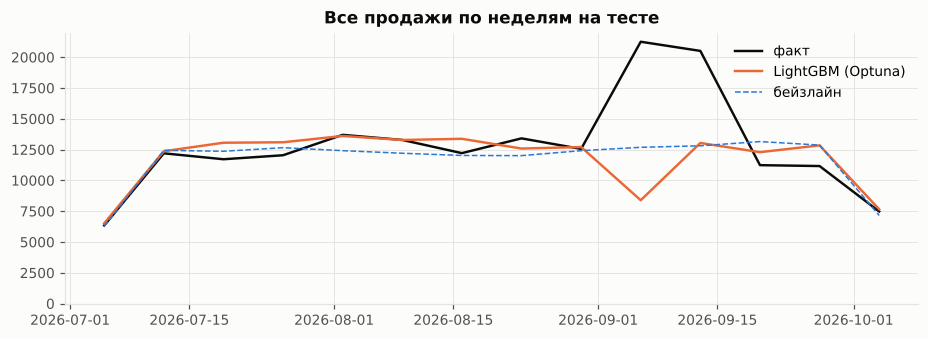

In [18]:
w = test.groupby(pd.Grouper(key='date', freq='W'))[['y', 'LightGBM_tuned', 'same_dow_4w']].sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(w.index, w.y, color=C.COLORS['actual'], label='факт')
ax.plot(w.index, w.LightGBM_tuned, color=C.COLORS['s2'], label='LightGBM (Optuna)')
ax.plot(w.index, w.same_dow_4w, color=C.COLORS['s1'], ls='--', lw=1, label='бейзлайн')
ax.set_title('Все продажи по неделям на тесте'); ax.set_ylim(bottom=0); ax.legend()
save(fig, 'model_test_weekly_total'); plt.show()

## 8. Важность признаков

Важность по **gain** — суммарное снижение функции потерь от разбиений по признаку во всех деревьях.

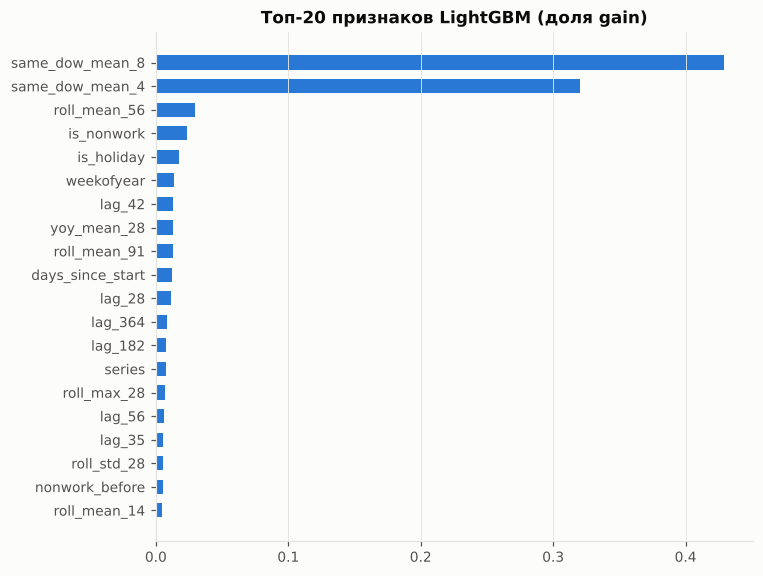

In [19]:
fi = tuned.feature_importance()
fi = (fi / fi.sum()).head(20).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(fi.index, fi.values, color=C.COLORS['s1'], height=0.6)
ax.set_title('Топ-20 признаков LightGBM (доля gain)'); ax.grid(axis='y', visible=False)
save(fig, 'model_feature_importance'); plt.show()

Больше половины «работы» модели делают признаки **уровня ряда по тому же дню недели**: `same_dow_mean_8` и `same_dow_mean_4`, средние за последние 8 и 4 известные недели. За ними идут лаги, кратные неделе (`lag_28` … `lag_56`), и **календарь**: нерабочий день, праздник, неделя года. Это совпадает с выводами EDA: продажи ≈ «уровень продукта × недельный и праздничный профиль». Модель по сути начинает с того же, что и хороший бейзлайн, и уточняет его календарём и трендом. Поэтому выигрыш сильнее всего виден именно в праздники.

## 9. Итоговая модель и прогноз на 28 дней вперёд

Обучаем LightGBM с подобранными параметрами на **всех** данных (до 30.09.2026) и строим прогноз на 01.10–28.10.2026. Те же шаги одной командой: `python -m src.pipeline` (сохраняет модель и прогноз для демо).

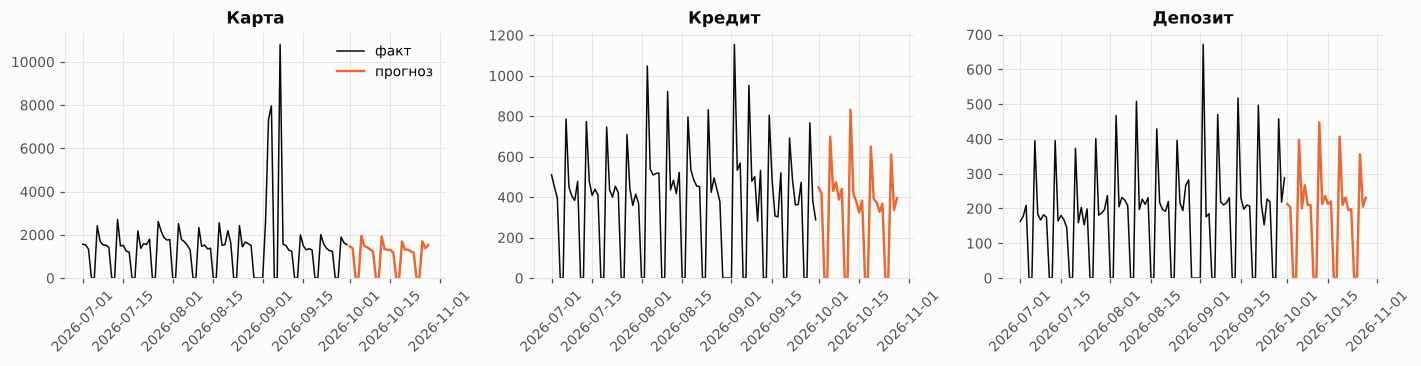

,прогноз на 28 дней
series,
Карта: Visa/MC массовые (именные + предвыпущенные),10386.0
Карта: Зарплатные,6689.0
Кредит: Онлайн кредит,5757.0
Карта: Виртуальные,4958.0
Карта: Нерезиденты,4790.0
Кредит: Экспресс и кредит наличными,3132.0
Депозит: Онлайн-вклады,2895.0
Депозит: Копилка (онлайн),1860.0
Карта: Кредитные / рассрочка,933.0


In [20]:
clean = feats[event_mask(feats)]          # без дней известных разовых событий
final = LGBMModel(**best).fit(clean[cols], clean['y'].values)
fut = build_features(add_future(df)); fut = fut[fut.y.isna()]
fc = fut[['date', 'product_group', 'series']].copy(); fc['forecast'] = final.predict(fut[cols])
hist = df[df.date >= '2026-07-01'].groupby(['product_group', 'date']).y.sum().unstack(0)
fcg = fc.groupby(['product_group', 'date']).forecast.sum().unstack(0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, pg in zip(axes, ['Карта', 'Кредит', 'Депозит']):
    ax.plot(hist.index, hist[pg], color=C.COLORS['actual'], lw=1, label='факт')
    ax.plot(fcg.index, fcg[pg], color=C.COLORS['s2'], label='прогноз')
    ax.set_title(pg); ax.set_ylim(bottom=0); ax.tick_params(axis='x', rotation=45)
axes[0].legend(); fig.tight_layout(); save(fig, 'model_forecast_next28'); plt.show()
fc.groupby('series').forecast.sum().round(0).sort_values(ascending=False).to_frame('прогноз на 28 дней')

## 10. Выводы и ограничения

**Что получилось**
* Глобальная модель LightGBM (37 признаков, подбор гиперпараметров в Optuna) прогнозирует дневные продажи 15 продуктов на 4 недели вперёд.
* Дневной WAPE относительно лучшего бейзлайна:
  * на валидации — 0,22 против 0,37;
  * на тесте — 0,32 против 0,36 по всем дням и 0,23 против 0,27 без разового события;
  * в скользящем бэктесте (13 прогнозов по 28 дней) — в среднем 0,32 против 0,47, модель лучше в 11 окнах из 13.
* Основной выигрыш даёт знание календаря, прежде всего праздников и длинных каникул. В дни после выходных модель пока ошибается чуть сильнее бейзлайна, и это первое, что стоит улучшать.

**Ограничения**
* Модель не знает о кампаниях, массовых выпусках карт и запуске зарплатных проектов — на таких днях она сильно недопрогнозирует. Решение — добавить календарь плановых кампаний как признак.
* На горизонте месяца выигрыш у простого бейзлайна пропадает; при резком росте ряда модель «догоняет» тренд с опозданием.
* Смена продуктов (новые продукты вместо старых) требует ручного объединения рядов — без этого модель увидит ложное падение.
* Ставки и условия продуктов в модель не входят (их будущие значения неизвестны); сценарный прогноз «что, если поднять ставку» — направление развития.
* Данные одного банка; в публичной версии объёмы обезличены.